# COU 07506 Digital Signal Processing
## Week 4 — z-Transform Laboratory: Poles, Zeros and Stability

**Name:** Deborah
**Registration Number:** 240242455798
**Class:** BEng24
**Date:** 26 November 2026

---

## Pre-lab Preparation

### Question (a)

Find the poles of:

H(z) = 1 / (1 - 0.9z⁻¹ + 0.81z⁻²)

Determine whether the causal system is stable.

**Answer:**

The denominator polynomial is:

z² - 0.9z + 0.81

The poles are the roots of this polynomial. Their magnitudes are both 0.9, which is less than 1.

Therefore, both poles lie inside the unit circle, and the causal system is stable.

### Question (b)

Find the partial fraction expansion of:

X(z) = 1 / [(1 - 0.5z⁻¹)(1 - 0.25z⁻¹)]

**Answer:**

The partial fraction expansion is:

X(z) = 2/(1 - 0.5z⁻¹) - 1/(1 - 0.25z⁻¹)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Question (a): Calculate poles
denominator = [1, -0.9, 0.81]
poles = np.roots(denominator)

print("Question (a)")
print("Poles:", poles)
print("Pole magnitudes:", np.abs(poles))
print("Stable:", np.all(np.abs(poles) < 1))

# Question (b): Partial fraction expansion
residues, poles_b, direct = signal.residuez(
    [1], [1, -0.75, 0.125]
)

print("\nQuestion (b)")
print("Residues:", residues)
print("Poles:", poles_b)
print("Direct term:", direct)

Question (a)
Poles: [0.45+0.77942286j 0.45-0.77942286j]
Pole magnitudes: [0.9 0.9]
Stable: True

Question (b)
Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []


## Task 4.1 — Pole-Zero Plotting

Poles and zeros describe important properties of a discrete-time system.

- Zeros are values of z that make the transfer-function numerator zero.
- Poles are values of z that make the transfer-function denominator zero.

The unit circle is used to assess the stability of causal discrete-time systems.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    theta = np.linspace(0, 2*np.pi, 400)

    ax.plot(np.cos(theta), np.sin(theta), "k--",
            linewidth=0.8, label="Unit circle")

    ax.plot(z.real, z.imag, "o", mfc="none",
            markersize=9, label="Zeros")

    ax.plot(p.real, p.imag, "x",
            markersize=9, mew=2, label="Poles")

    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)

    ax.set_aspect("equal")
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.grid()
    ax.legend()

    return z, p

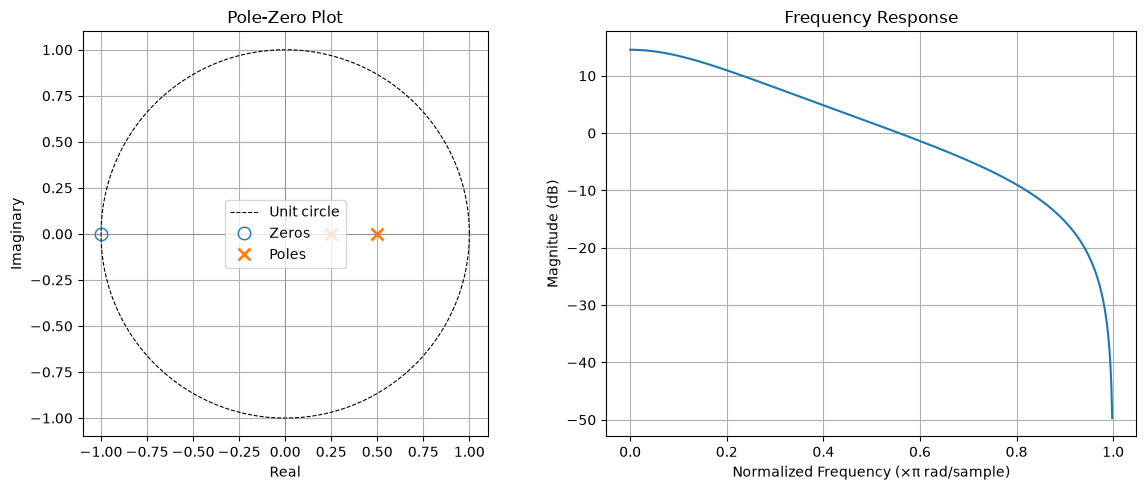

Zeros: [-1.]
Poles: [0.5  0.25]
Pole magnitudes: [0.5  0.25]
System is stable: True


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

b = [1, 1]
a = [1, -0.75, 0.125]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

zeros, poles = zplane(b, a, axes[0])
axes[0].set_title("Pole-Zero Plot")

w, H = signal.freqz(b, a, worN=512)

axes[1].plot(w/np.pi, 20*np.log10(np.maximum(np.abs(H), 1e-12)))
axes[1].set_title("Frequency Response")
axes[1].set_xlabel("Normalized Frequency (×π rad/sample)")
axes[1].set_ylabel("Magnitude (dB)")
axes[1].grid()

plt.tight_layout()
plt.show()

print("Zeros:", zeros)
print("Poles:", poles)
print("Pole magnitudes:", np.abs(poles))
print("System is stable:", np.all(np.abs(poles) < 1))

## Task 4.2 — Inverse z-Transform Using Partial Fractions

Use partial fraction expansion to obtain the inverse z-transform of a transfer function.

Compare the impulse response obtained from the partial fraction expansion with the response calculated using `scipy.signal.lfilter`.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

b = [1]
a = [1, -0.75, 0.125]

r, p, k = signal.residuez(b, a)

n = np.arange(10)

h_partial = np.zeros(len(n), dtype=complex)

for ri, pi in zip(r, p):
    h_partial += ri * pi**n

h_partial = h_partial.real

impulse = np.zeros(10)
impulse[0] = 1

h_lfilter = signal.lfilter(b, a, impulse)

print("Residues:", r)
print("Poles:", p)
print("Direct term:", k)

print("\nPartial fraction response:")
print(h_partial)

print("\nlfilter response:")
print(h_lfilter)

print("\nResults match:", np.allclose(h_partial, h_lfilter))

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []

Partial fraction response:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

lfilter response:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Results match: True


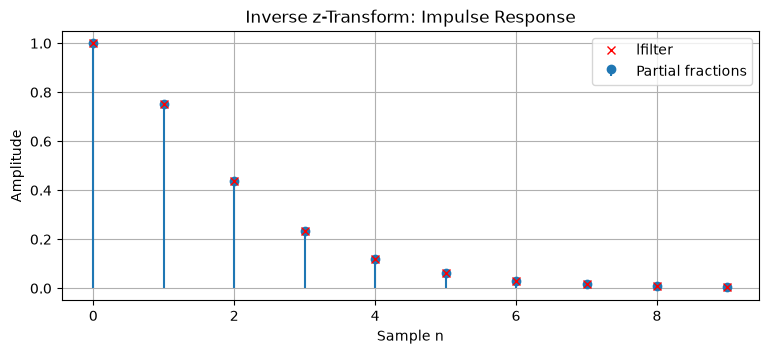

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

plt.figure()

plt.stem(n, h_partial, linefmt="C0-", markerfmt="C0o",
         basefmt=" ", label="Partial fractions")

plt.plot(n, h_lfilter, "rx", label="lfilter")

plt.title("Inverse z-Transform: Impulse Response")
plt.xlabel("Sample n")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

b = [1, 1]
a = [1, -0.75, 0.125]

r, p, k = signal.residuez(b, a)

h_partial_2 = np.zeros(len(n), dtype=complex)

for ri, pi in zip(r, p):
    h_partial_2 += ri * pi**n

h_partial_2 = h_partial_2.real

h_lfilter_2 = signal.lfilter(b, a, impulse)

h_theoretical = 6*(0.5**n) - 5*(0.25**n)

print("Residues:", r)
print("Poles:", p)
print("Partial fractions:", h_partial_2)
print("lfilter:", h_lfilter_2)
print("Theoretical:", h_theoretical)

print("Partial fractions match lfilter:",
      np.allclose(h_partial_2, h_lfilter_2))

print("Theoretical expression matches:",
      np.allclose(h_partial_2, h_theoretical))

Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Partial fractions: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Theoretical: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Partial fractions match lfilter: True
Theoretical expression matches: True


### Observations

The inverse z-transform obtained using partial fractions agrees with the impulse response calculated using `lfilter`.

For the transfer function in Task 4.1, the theoretical impulse response is:

h(n) = 6(0.5)^n - 5(0.25)^n

The agreement between the three methods verifies the inverse z-transform calculation.

## Task 4.3 — Effect of Pole Radius on System Response

Consider a complex conjugate pole pair:

p = r e^(±jπ/4)

The denominator is:

A(z) = 1 - 2r cos(π/4)z⁻¹ + r²z⁻²

Investigate the system for r = 0.5, 0.8, 0.95, 1.0 and 1.05.

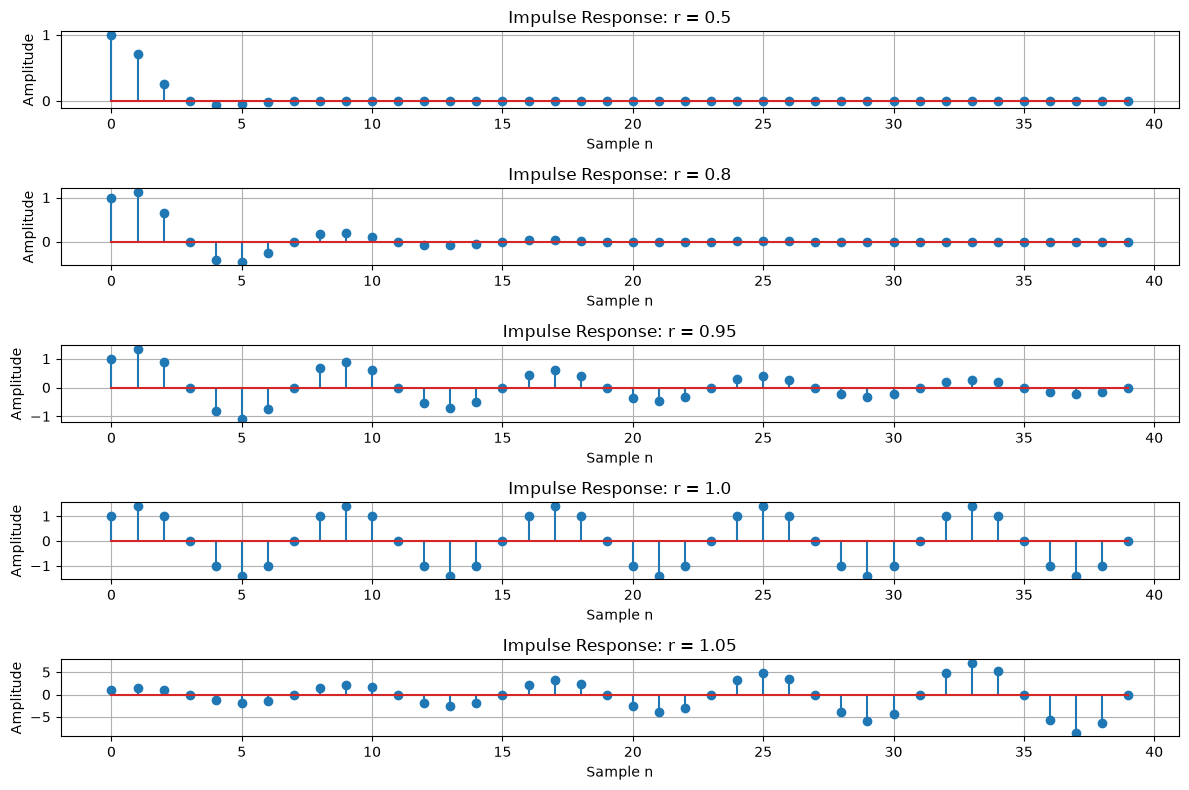

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
n = np.arange(40)

plt.figure(figsize=(12, 8))

for i, r in enumerate(r_values, start=1):
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    b = [1]

    impulse = np.zeros(40)
    impulse[0] = 1

    h = signal.lfilter(b, a, impulse)

    plt.subplot(5, 1, i)
    plt.stem(n, h)
    plt.title(f"Impulse Response: r = {r}")
    plt.xlabel("Sample n")
    plt.ylabel("Amplitude")
    plt.grid()

plt.tight_layout()
plt.show()

/home/deborah/Documents/COU07506-DSP/.venv/lib/python3.14/site-packages/scipy/signal/_filter_design.py:566: RuntimeWarning: divide by zero encountered in divide
  h = (_pu.npp_polyval(zm1, b, tensor=False, xp=xp) /
/home/deborah/Documents/COU07506-DSP/.venv/lib/python3.14/site-packages/scipy/signal/_filter_design.py:566: RuntimeWarning: invalid value encountered in divide
  h = (_pu.npp_polyval(zm1, b, tensor=False, xp=xp) /


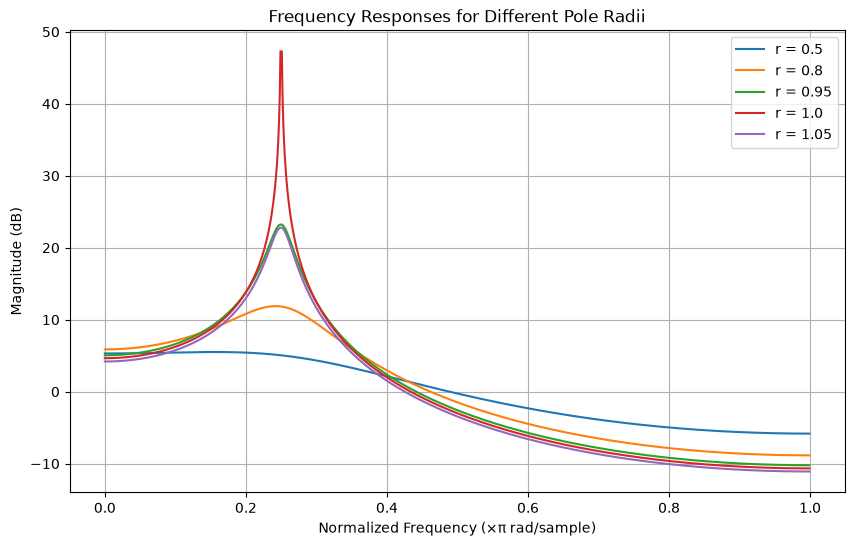

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

plt.figure(figsize=(10, 6))

for r in r_values:
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    b = [1]

    w, H = signal.freqz(b, a, worN=1024)

    magnitude_db = 20*np.log10(np.maximum(np.abs(H), 1e-12))

    plt.plot(w/np.pi, magnitude_db, label=f"r = {r}")

plt.title("Frequency Responses for Different Pole Radii")
plt.xlabel("Normalized Frequency (×π rad/sample)")
plt.ylabel("Magnitude (dB)")
plt.legend()
plt.grid()
plt.show()

### Observations

- r = 0.5: The impulse response decays quickly.
- r = 0.8: The impulse response decays more slowly.
- r = 0.95: The response decays very slowly and produces a sharper resonance.
- r = 1.0: The poles lie on the unit circle, producing sustained oscillations.
- r = 1.05: The response grows with time, indicating instability.

As the pole radius approaches 1 from below, the frequency response becomes increasingly sharp around the resonant frequency.

For a causal system, stability requires all poles to lie strictly inside the unit circle.

## Task 4.4 — Stability Classification

Investigate the stability of four discrete-time systems by calculating their poles, plotting their pole-zero diagrams, and examining their impulse responses.

A causal rational system is BIBO stable if all its poles lie strictly inside the unit circle.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

for name, (b, a) in systems.items():
    poles = np.roots(a)
    stable = np.all(np.abs(poles) < 1)

    print(f"{name}")
    print("Poles:", poles)
    print("Pole magnitudes:", np.abs(poles))
    print("BIBO stable:", stable)
    print("-" * 35)

H1
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.94339811 0.94339811]
BIBO stable: True
-----------------------------------
H2
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
BIBO stable: False
-----------------------------------
H3
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
BIBO stable: False
-----------------------------------
H4
Poles: []
Pole magnitudes: []
BIBO stable: True
-----------------------------------


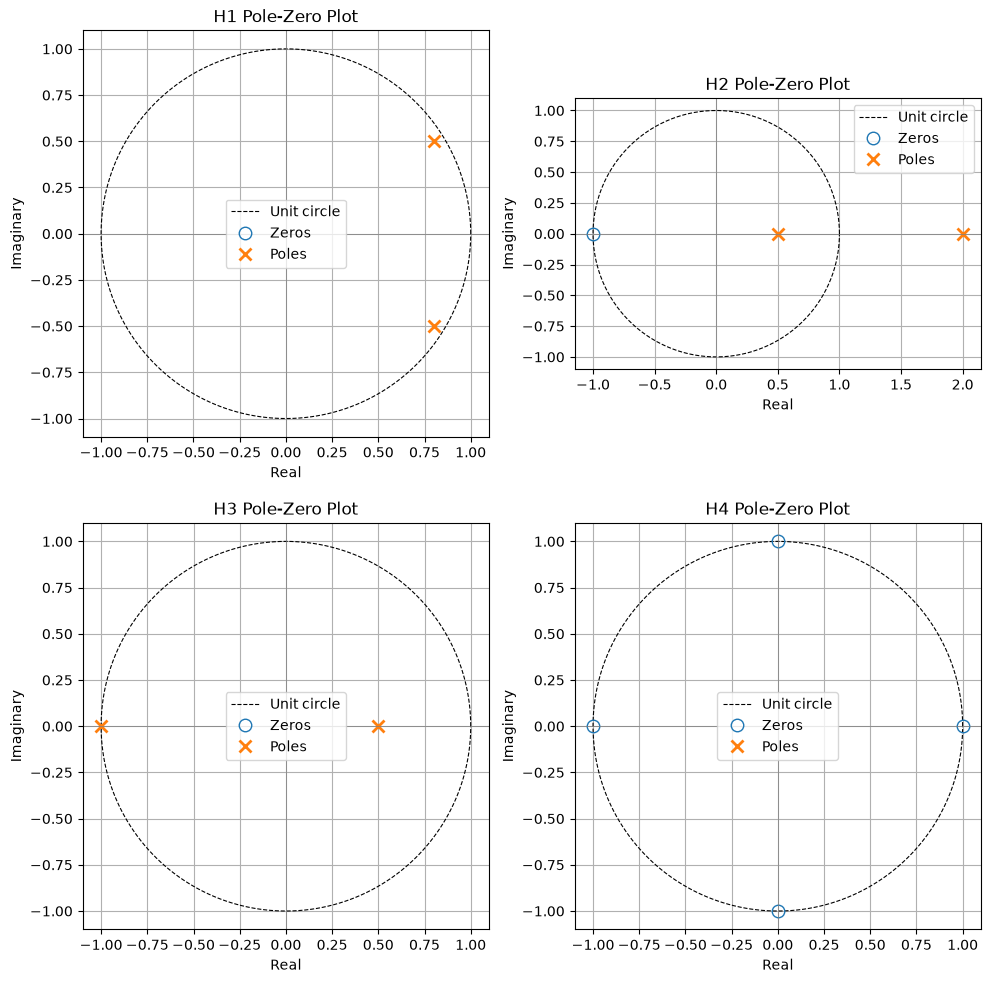

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):
    z, p = zplane(b, a, ax)
    ax.set_title(f"{name} Pole-Zero Plot")

plt.tight_layout()
plt.show()

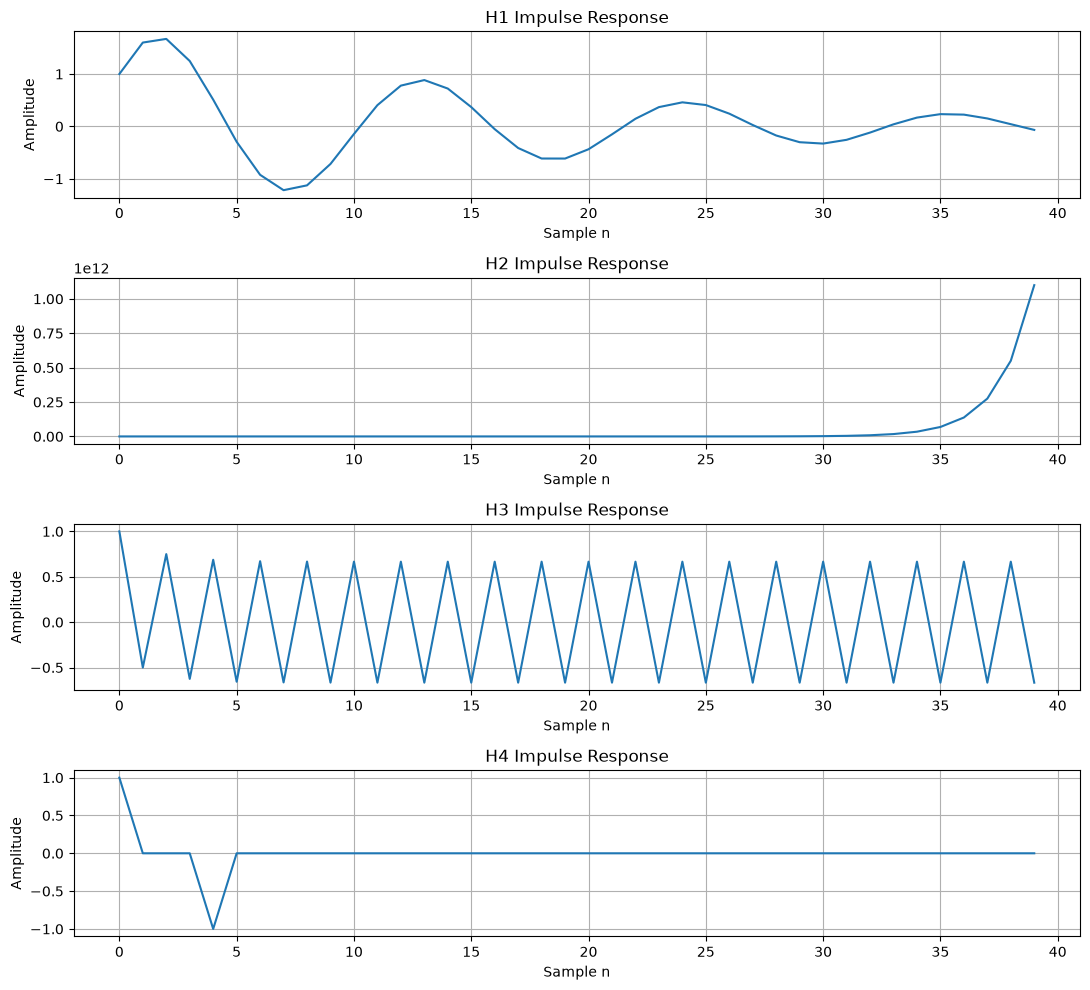

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

N = 40
impulse = np.zeros(N)
impulse[0] = 1

fig, axes = plt.subplots(4, 1, figsize=(11, 10))

for ax, (name, (b, a)) in zip(axes, systems.items()):
    h = signal.lfilter(b, a, impulse)

    ax.plot(np.arange(N), h)
    ax.set_title(f"{name} Impulse Response")
    ax.set_xlabel("Sample n")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()

### Stability Classification

- H1: Stable. Both poles are inside the unit circle.
- H2: Unstable. One pole lies outside the unit circle.
- H3: Unstable in the BIBO sense. One pole lies on the unit circle.
- H4: Stable. It is an FIR system with a finite impulse response.

A pole on the unit circle produces a non-decaying impulse response, which is not absolutely summable. Therefore, the system is not BIBO stable.

## Task 4.5 — Design a Digital Resonator

Design a digital resonator with the following specifications:

- Centre frequency: 1 kHz
- Sampling frequency: 8 kHz
- Pole radius: r = 0.97
- Zeros at z = +1 and z = -1

The resonator will be analysed using its pole-zero plot and frequency response. White noise will then be passed through the system to demonstrate its resonant behaviour.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

fs = 8000
f0 = 1000
r = 0.97

theta = 2*np.pi*f0/fs

b_res = [1, 0, -1]
a_res = [1, -2*r*np.cos(theta), r**2]

print("Numerator coefficients:", b_res)
print("Denominator coefficients:", a_res)
print("Centre frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Pole radius:", r)

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]
Centre frequency: 1000 Hz
Sampling frequency: 8000 Hz
Pole radius: 0.97


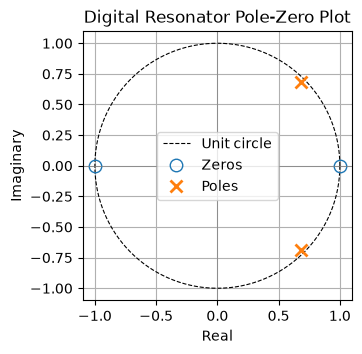

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Pole magnitudes: [0.97 0.97]
System is stable: True


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

plt.figure()
z, p = zplane(b_res, a_res)

plt.title("Digital Resonator Pole-Zero Plot")
plt.show()

print("Zeros:", z)
print("Poles:", p)
print("Pole magnitudes:", np.abs(p))
print("System is stable:", np.all(np.abs(p) < 1))

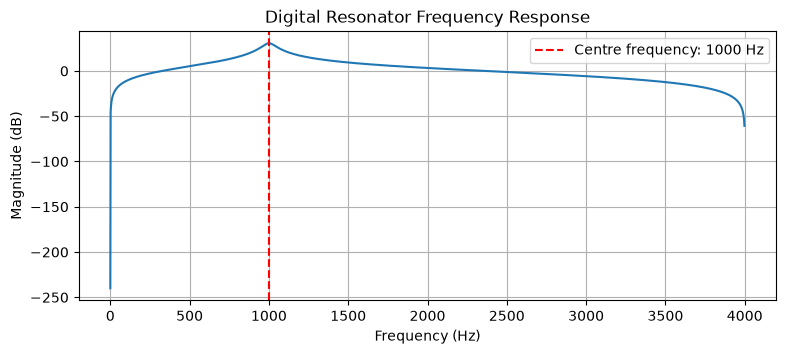

Peak frequency: 1000.0 Hz


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

w, H = signal.freqz(b_res, a_res, worN=2048, fs=fs)

magnitude_db = 20*np.log10(np.maximum(np.abs(H), 1e-12))

plt.figure()
plt.plot(w, magnitude_db)

plt.axvline(f0, color="red", linestyle="--",
            label="Centre frequency: 1000 Hz")

plt.title("Digital Resonator Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.legend()
plt.grid()
plt.show()

peak_frequency = w[np.argmax(np.abs(H))]
print("Peak frequency:", peak_frequency, "Hz")

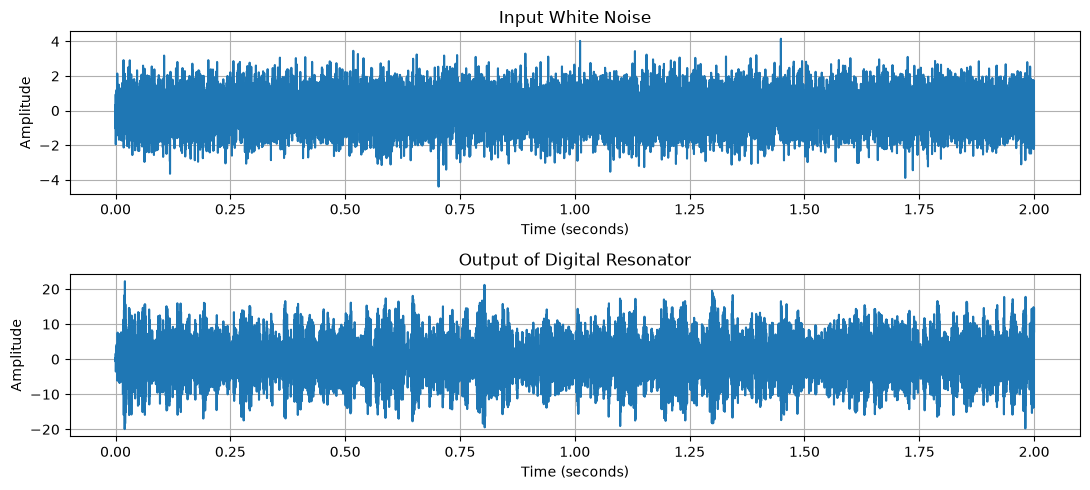

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

rng = np.random.default_rng(42)

duration = 2
white_noise = rng.standard_normal(fs*duration)

resonator_output = signal.lfilter(
    b_res, a_res, white_noise
)

plt.figure(figsize=(11, 5))

plt.subplot(2, 1, 1)
plt.plot(np.arange(len(white_noise))/fs, white_noise)
plt.title("Input White Noise")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(np.arange(len(resonator_output))/fs, resonator_output)
plt.title("Output of Digital Resonator")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

display(Audio(resonator_output, rate=fs))

### Observations

- The poles are located close to the unit circle, at angles corresponding to the 1 kHz centre frequency.
- The zeros at z = +1 and z = -1 suppress the DC and Nyquist frequencies.
- The frequency response has a strong resonance around 1 kHz.
- Passing white noise through the resonator emphasizes frequency components near 1 kHz.
- The system is stable because its pole radius is 0.97, which is less than 1.

## Week 4 — Analysis Questions

### Question 1
What happens to the bandwidth of a resonator as the pole radius approaches 1?

**Answer:**

As the pole radius approaches 1 from below, the resonator bandwidth becomes narrower and its frequency response becomes sharper. The resonance becomes more pronounced. When the pole radius reaches or exceeds 1, the causal system is no longer BIBO stable.

### Question 2
Why is a pole exactly on the unit circle considered unstable?

**Answer:**

A pole on the unit circle produces an impulse response that does not decay sufficiently for absolute summability. Consequently, the system does not satisfy the BIBO stability condition.

### Question 3
Why are zeros placed at z = +1 and z = -1 in Task 4.5?

**Answer:**

The zero at z = +1 suppresses the DC component (0 Hz), while the zero at z = -1 suppresses the Nyquist frequency (4 kHz for an 8 kHz sampling rate). This creates a band-pass response that emphasizes frequencies around the resonator's 1 kHz centre frequency.

### Question 4
Verify the stability of systems H1, H2 and H3 in Task 4.4 using the stability condition.

**Answer:**

- H1: Stable because both poles have magnitudes less than 1.
- H2: Unstable because one pole has magnitude greater than 1.
- H3: Unstable because one pole lies exactly on the unit circle.

A causal rational discrete-time system is BIBO stable only when all its poles lie strictly inside the unit circle.

## AI-Use Statement

AI tools used: ChatGPT.

Used for: Understanding laboratory instructions, explaining z-transform concepts, and receiving guidance on Python code implementation.

How I verified the output: I executed the code cells in JupyterLab and checked the pole-zero plots, calculated poles, frequency responses, impulse responses, stability classifications, and resonator output.

I confirm that I understand and can explain all submitted code.